In [ ]:
%pip install -q kagglehub

In [ ]:
from pathlib import Path
import csv
import hashlib
import json
import random
import shutil
import kagglehub

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from google.colab import drive, files

In [ ]:
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
CLASS_NAMES = ["Cyst", "Normal", "Stone", "Tumor"]

keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
drive.mount("/content/drive")

path = kagglehub.dataset_download("nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone")
print("Path to dataset files:", path)

data_dir = Path(path)
split_dir = Path("/content/kidney_split")
results_dir = Path("/content/classification_results")
export_dir = Path("/content/drive/MyDrive/kidney-classification")

results_dir.mkdir(parents=True, exist_ok=True)
export_dir.mkdir(parents=True, exist_ok=True)
model_path = export_dir / "kidney_classifier.keras"

candidates = [data_dir] + sorted(
    path for path in data_dir.rglob("*") if path.is_dir()
)
dataset_root = next(
    (path for path in candidates if all((path / name).is_dir() for name in CLASS_NAMES)),None
)

if dataset_root is None:
    raise FileNotFoundError("Could not find Cyst, Normal, Stone, and Tumor folders.")

print("Dataset:", dataset_root)

Mounted at /content/drive
Using Colab cache for faster access to the 'ct-kidney-dataset-normal-cyst-tumor-and-stone' dataset.
Path to dataset files: /kaggle/input/ct-kidney-dataset-normal-cyst-tumor-and-stone
Dataset: /kaggle/input/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone


Removed duplicate copies: 517
train {'Cyst': 2298, 'Normal': 3501, 'Stone': 951, 'Tumor': 1598}
validation {'Cyst': 492, 'Normal': 750, 'Stone': 204, 'Tumor': 342}
test {'Cyst': 494, 'Normal': 751, 'Stone': 205, 'Tumor': 343}


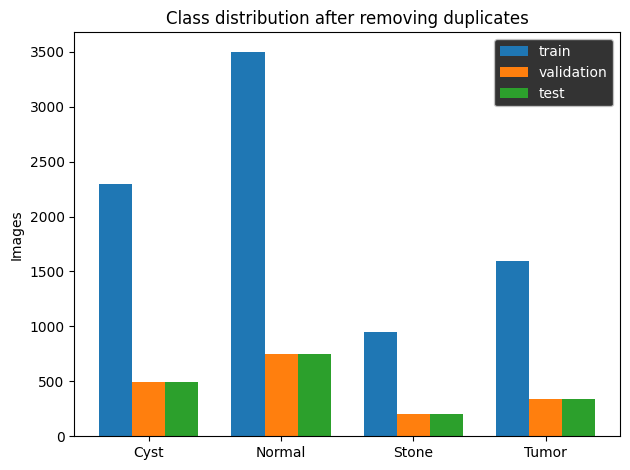

In [ ]:
if split_dir.exists():
    shutil.rmtree(split_dir)

seen = {}
duplicates = 0
counts = {
    split: [] for split in ["train", "validation", "test"]
}
manifest = []
rng = random.Random(SEED)

for class_name in CLASS_NAMES:
    unique_paths = []
    paths = sorted(
        path for path in (dataset_root / class_name).rglob("*")
        if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    )

    if not paths:
        raise ValueError(f"No images found for {class_name}")

    for path in paths:
        with keras.utils.load_img(path, color_mode="rgb") as image:
            digest = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()

        if digest in seen:
            if seen[digest] != class_name:
                raise ValueError(
                    f"An identical image has conflicting class labels: {path}"
                )

            duplicates += 1
            continue

        seen[digest] = class_name
        unique_paths.append(path)

    rng.shuffle(unique_paths)
    train_end = int(len(unique_paths) * 0.70)
    val_end = train_end + int(len(unique_paths) * 0.15)
    subsets = {
        "train": unique_paths[:train_end],
        "validation": unique_paths[train_end:val_end],
        "test": unique_paths[val_end:]
    }

    for split, subset in subsets.items():
        destination = split_dir / split / class_name
        destination.mkdir(parents=True, exist_ok=True)
        counts[split].append(len(subset))

        for index, path in enumerate(subset):
            shutil.copy2(
                path, destination / f"{index:05d}{path.suffix.lower()}"
            )
            manifest.append(
                [split, class_name, str(path.relative_to(dataset_root))]
            )

with (results_dir / "split_manifest.csv").open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["split", "class", "source_image"])
    writer.writerows(manifest)

print("Removed duplicate copies:", duplicates)

for split, values in counts.items():
    print(split, dict(zip(CLASS_NAMES, values)))

x = np.arange(len(CLASS_NAMES))

for offset, (split, values) in enumerate(counts.items()):
    plt.bar(x + (offset - 1) * 0.25, values, width=0.25, label=split)

plt.style.use('dark_background')
plt.xticks(x, CLASS_NAMES)
plt.ylabel("Images")
plt.title("Class distribution after removing duplicates")
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "class_distribution.png", dpi=150)
plt.show()

Found 8348 files belonging to 4 classes.
Found 1788 files belonging to 4 classes.
Found 1793 files belonging to 4 classes.


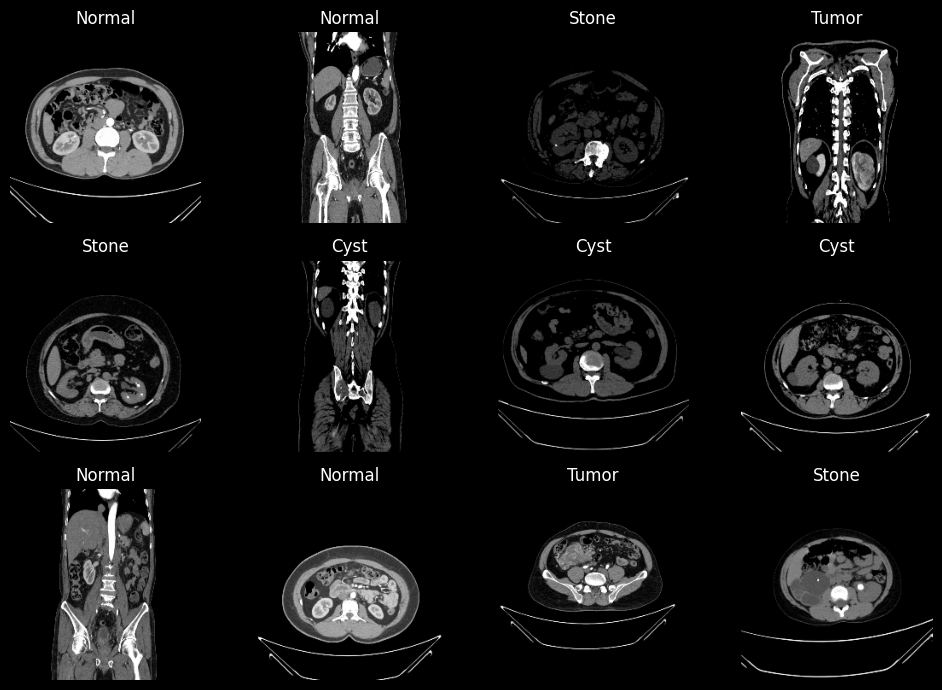

In [ ]:
def load_dataset(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        split_dir / split,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

train_data = load_dataset("train", shuffle=True)
val_data = load_dataset("validation", shuffle=False)
test_data = load_dataset("test", shuffle=False)
test_paths = test_data.file_paths

plt.figure(figsize=(10, 7))
images, labels = next(iter(train_data))

for index in range(min(12, len(images))):
    plt.subplot(3, 4, index + 1)
    plt.imshow(images[index].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(labels[index])])
    plt.axis("off")

plt.tight_layout()
plt.savefig(results_dir / "dataset_examples.png", dpi=150)
plt.show()

train_data = train_data.prefetch(tf.data.AUTOTUNE)
val_data = val_data.prefetch(tf.data.AUTOTUNE)
test_data = test_data.prefetch(tf.data.AUTOTUNE)

In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(*IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

model = keras.Sequential([
    keras.Input(shape=(*IMAGE_SIZE, 3)),
    keras.layers.RandomFlip("horizontal", seed=SEED),
    keras.layers.RandomRotation(0.03, seed=SEED),
    keras.layers.Rescaling(1 / 127.5, offset=-1),
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
train_counts = np.array(counts["train"])
class_weights = {
    index: float(train_counts.sum() / (len(CLASS_NAMES) * count))
    for index, count in enumerate(train_counts)
}

callbacks = [
    keras.callbacks.ModelCheckpoint(str(model_path), monitor="val_loss", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 34s 113ms/step - accuracy: 0.6906 - loss: 0.7925 - val_accuracy: 0.8126 - val_loss: 0.5279 - learning_rate: 0.0010
Epoch 2/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - accuracy: 0.8410 - loss: 0.4647 - val_accuracy: 0.8484 - val_loss: 0.4220 - learning_rate: 0.0010
Epoch 3/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - accuracy: 0.8705 - loss: 0.3755 - val_accuracy: 0.8585 - val_loss: 0.4048 - learning_rate: 0.0010
Epoch 4/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - accuracy: 0.8845 - loss: 0.3316 - val_accuracy: 0.8686 - val_loss: 0.3534 - learning_rate: 0.0010
Epoch 5/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - accuracy: 0.9006 - loss: 0.2935 - val_accuracy: 0.8954 - val_loss: 0.3050 - learning_rate: 0.0010
Epoch 6/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 28s 106ms/step - accuracy: 0.9079 - loss: 0.2733 - val_accuracy: 0.8725 - val_loss: 0.3299 - learning_rate: 0.0010
Epoch 7/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 32s 122ms/step - accuracy: 0.9

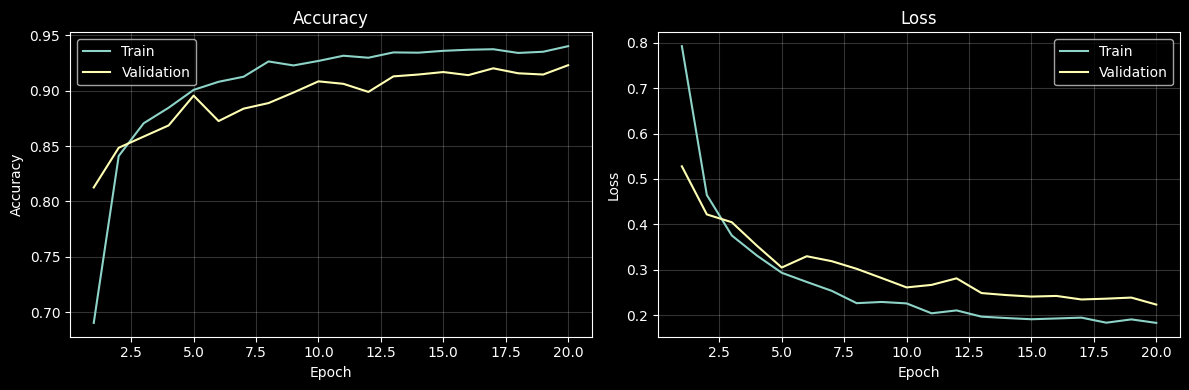

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["accuracy", "loss"]):
    epochs = range(1, len(history.history[metric]) + 1)
    ax.plot(epochs, history.history[metric], label="Train")
    ax.plot(epochs, history.history[f"val_{metric}"], label="Validation")
    ax.set(xlabel="Epoch", ylabel=metric.capitalize(), title=metric.capitalize())
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(results_dir / "training_curves.png", dpi=150)
plt.show()

57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.9325 - loss: 0.2054
Test accuracy: 93.25%
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step
Class       Precision     Recall         F1    Support
Cyst            0.936      0.978      0.956        494
Normal          0.969      0.923      0.945        751
Stone           0.802      0.946      0.868        205
Tumor           0.944      0.880      0.911        343
Macro F1: 0.920


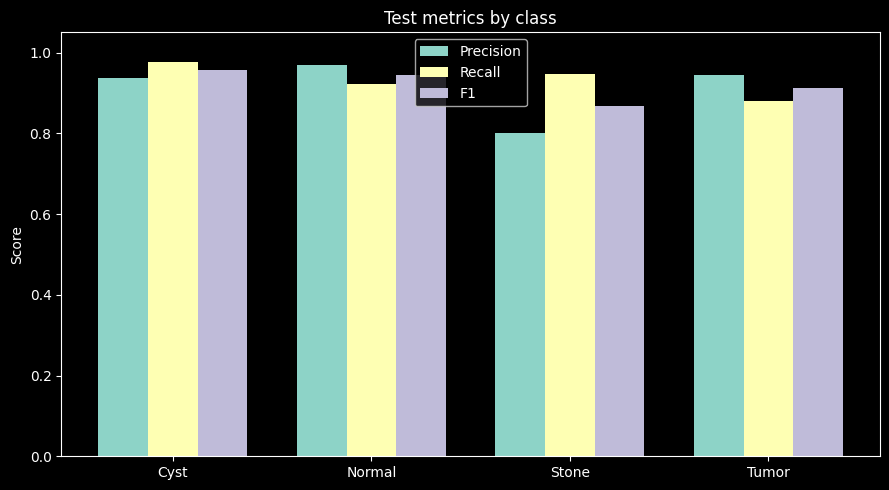

In [ ]:
model = keras.models.load_model(model_path)
test_metrics = model.evaluate(test_data, return_dict=True)
print(f"Test accuracy: {test_metrics['accuracy']:.2%}")

probabilities = model.predict(test_data)
y_pred = probabilities.argmax(axis=1)
y_true = np.concatenate([labels.numpy() for _, labels in test_data])
matrix = tf.math.confusion_matrix(y_true, y_pred, num_classes=len(CLASS_NAMES)).numpy()

true_positive = np.diag(matrix).astype(float)
precision = true_positive / np.maximum(matrix.sum(axis=0), 1)
recall = true_positive / np.maximum(matrix.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-8)

print(f"{'Class':10} {'Precision':>10} {'Recall':>10} {'F1':>10} {'Support':>10}")

for index, name in enumerate(CLASS_NAMES):
    print(f"{name:10} {precision[index]:10.3f} {recall[index]:10.3f} "
          f"{f1[index]:10.3f} {matrix[index].sum():10d}")

print(f"Macro F1: {f1.mean():.3f}")

plt.figure(figsize=(9, 5))
x = np.arange(len(CLASS_NAMES))

for offset, (name, values) in enumerate(
        [("Precision", precision),
         ("Recall", recall),
         ("F1", f1)]
):
    plt.bar(x + (offset - 1) * 0.25, values, width=0.25, label=name)

plt.xticks(x, CLASS_NAMES)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Test metrics by class")
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "class_metrics.png", dpi=150)
plt.show()

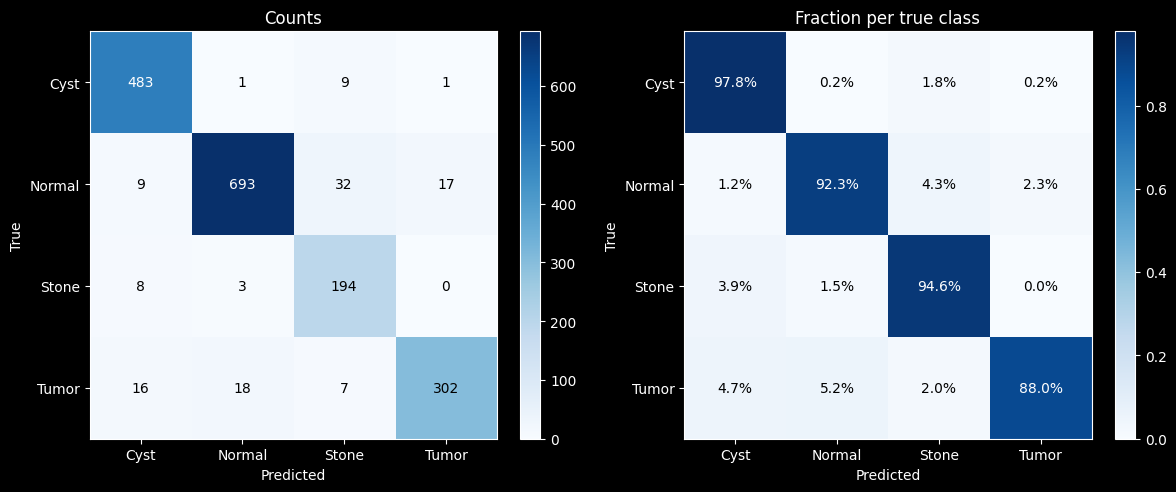

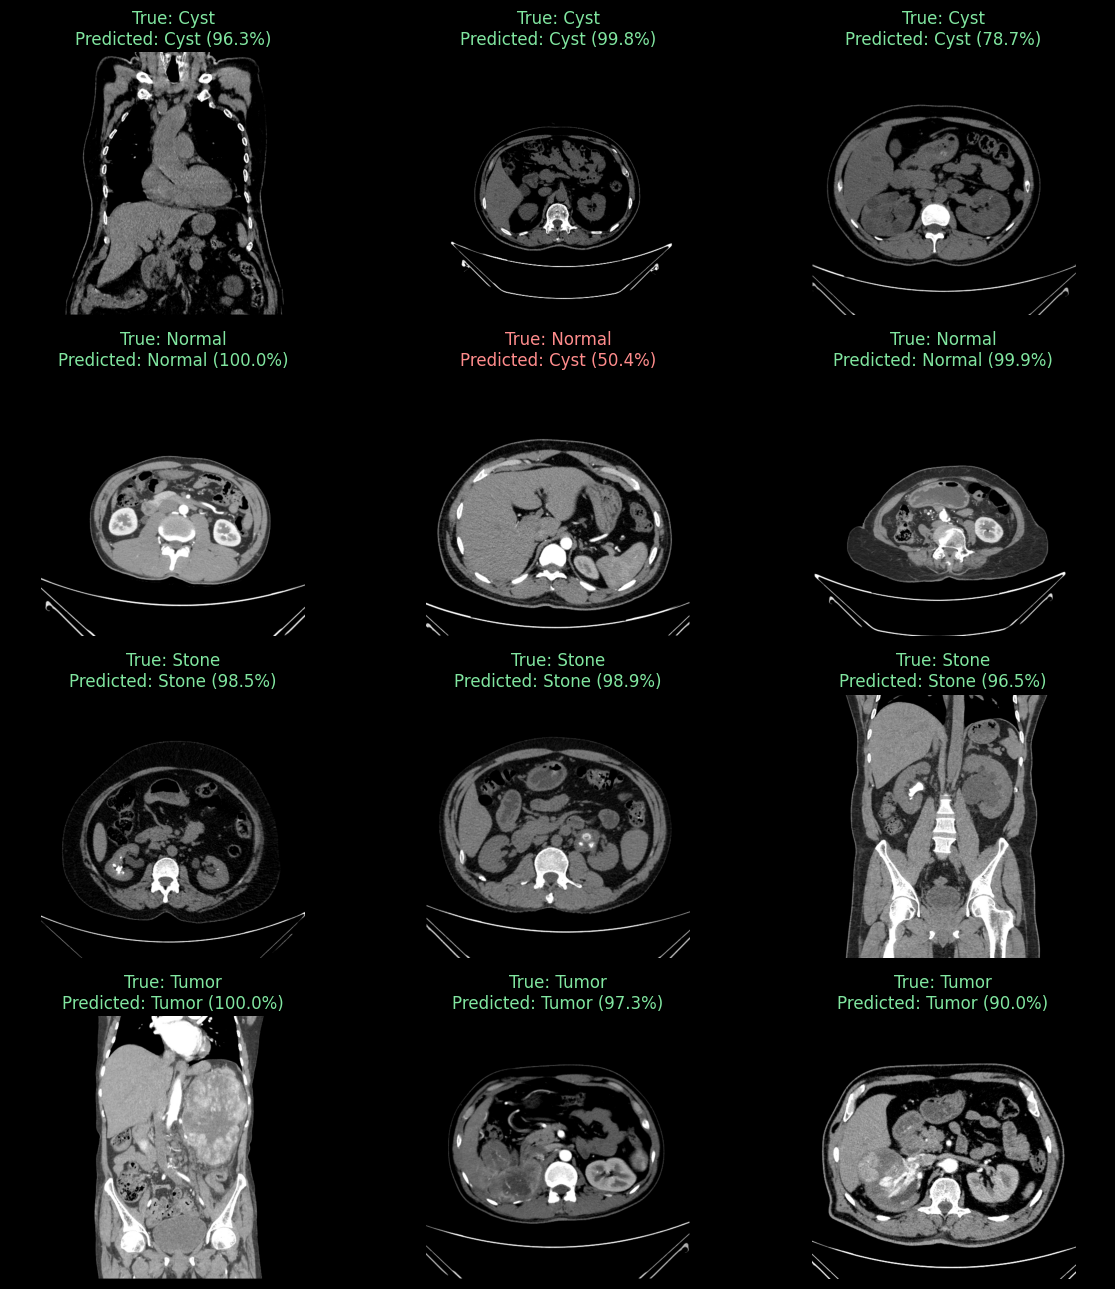

In [ ]:
normalized_matrix = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, values, title in zip(axes, [matrix, normalized_matrix], ["Counts", "Fraction per true class"]):
    plot = ax.imshow(values, cmap="Blues")
    fig.colorbar(plot, ax=ax, fraction=0.046)
    ax.set(
        xticks=range(4),
        yticks=range(4),
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        xlabel="Predicted",
        ylabel="True",
        title=title
    )

    for row in range(4):
        for col in range(4):
            label = str(matrix[row, col]) if title == "Counts" else f"{values[row, col]:.1%}"
            ax.text(
                col,
                row,
                label,
                ha="center",
                va="center",
                color="white" if values[row, col] > values.max() / 2 else "black"
            )
fig.tight_layout()
fig.savefig(results_dir / "confusion_matrix.png", dpi=150)
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(12, 13))

for class_index in range(4):
    indices = np.where(y_true == class_index)[0]
    chosen = np.random.default_rng(SEED).choice(indices, size=min(3, len(indices)), replace=False)

    for col, ax in enumerate(axes[class_index]):
        ax.axis("off")

        if col >= len(chosen):
            continue

        index = chosen[col]

        with keras.utils.load_img(test_paths[index]) as image:
            ax.imshow(image)

        predicted = y_pred[index]
        ax.set_title(f"True: {CLASS_NAMES[class_index]}\n"
                     f"Predicted: {CLASS_NAMES[predicted]} ({probabilities[index, predicted]:.1%})",
                     color="#81e6a0" if predicted == class_index else "#ff8c8c")

fig.tight_layout()
fig.savefig(results_dir / "prediction_examples.png", dpi=150)
plt.show()

In [ ]:
model_info = {
    "architecture": "MobileNetV2 with frozen ImageNet features and a four-class head",
    "class_names": CLASS_NAMES,
    "image_size": list(IMAGE_SIZE),
    "color_mode": "RGB",
    "input_range": [0, 255],
    "preprocessing": "Rescaling to [-1, 1] is included in the model"
}
metrics = {
    "test": {name: float(value) for name, value in test_metrics.items()},
    "macro_precision": float(precision.mean()),
    "macro_recall": float(recall.mean()),
    "macro_f1": float(f1.mean()),
    "per_class": {
        name: {
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(f1[i]),
            "support": int(matrix[i].sum())
        } for i, name in enumerate(CLASS_NAMES)
    },
    "confusion_matrix": matrix.tolist()
}
history_values = {
    key: [float(value) for value in values] for key, values in history.history.items()
}

for filename, content in [
    ("model_info.json", model_info),
    ("metrics.json", metrics),
    ("history.json", history_values)
]:
    (results_dir / filename).write_text(json.dumps(content, indent=2))
shutil.copy2(results_dir / "model_info.json", export_dir / "model_info.json")

results_zip = shutil.make_archive("/content/classification_results", "zip", results_dir)
shutil.copy2(results_zip, export_dir / "classification_results.zip")

print("Best model:", model_path)
print("Model information:", export_dir / "model_info.json")
print("Results:", export_dir / "classification_results.zip")

files.download(str(model_path))
files.download(results_zip)

Best model: /content/drive/MyDrive/kidney-classification/kidney_classifier.keras
Model information: /content/drive/MyDrive/kidney-classification/model_info.json
Results: /content/drive/MyDrive/kidney-classification/classification_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>